# Week 2: Customer Segmentation & Behavioral Analytics
**Data Analytics Internship Capstone Project**  
*Author:* Data Analytics Intern  
*Objective:* Perform customer segmentation using **RFM Analysis**, **K-Means Clustering**, and **Principal Component Analysis (PCA)** with scikit-learn to identify distinct customer behavioral archetypes and formulate targeted marketing playbooks.

---

### Core Methodology:
1. **Feature Engineering**: Recency, Frequency, Monetary (RFM), Annual Income, Spending Score, and Web Engagement
2. **Data Scaling**: Z-score Standardization (StandardScaler)
3. **Cluster Optimization**: Within-Cluster Sum of Squares (Elbow Method) & Silhouette Score maximization
4. **Dimensionality Reduction**: 2D & 3D PCA projection
5. **Business Playbook**: Tailored marketing strategies for each customer persona


In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score
from sklearn.decomposition import PCA

# Plot aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

print('Machine learning and analytics libraries initialized successfully!')

Machine learning and analytics libraries initialized successfully!


## 1. Data Ingestion & Quality Inspection
Loading the raw multi-dimensional customer dataset.

In [2]:
csv_path = '../data/raw/customer_data.csv'
df = pd.read_csv(csv_path)

print(f'Customer Database Size: {df.shape[0]:,} profiles across {df.shape[1]} attributes')
print('\n--- Missing Value Audit ---')
print(df.isnull().sum())
df.head()

Customer Database Size: 2,000 profiles across 19 attributes

--- Missing Value Audit ---
Customer_ID             0
Customer_Name           0
Gender                  0
Age                     0
Region                  0
City                    0
Annual_Income           0
Spending_Score          0
Recency_Days            0
Frequency               0
Monetary_Total          0
AOV                     0
Tenure_Months           0
Preferred_Category      0
Web_Visits_Per_Month    0
Discount_Sensitivity    0
Loyalty_Member          0
Return_Rate_Pct         0
True_Archetype          0
dtype: int64


,Customer_ID,Customer_Name,Gender,Age,Region,City,Annual_Income,Spending_Score,Recency_Days,Frequency,Monetary_Total,AOV,Tenure_Months,Preferred_Category,Web_Visits_Per_Month,Discount_Sensitivity,Loyalty_Member,Return_Rate_Pct,True_Archetype
0,CUST-2001,Maya Vance,Male,41,West,San Francisco,36755.62,41,17,13,2267.42,174.42,12,Fashion & Apparel,25,High,No,6.50,Bargain Hunter
1,CUST-2002,Kavita Mercer,Female,25,West,Portland,60000.68,65,17,11,7775.42,706.86,24,Technology,18,Medium,Yes,9.00,Tech Enthusiast
2,CUST-2003,Diego Rao,Female,25,East,New York City,25289.27,49,20,8,3635.69,454.46,19,Furniture,21,High,No,9.70,Bargain Hunter
3,CUST-2004,Sienna Watanabe,Female,35,West,Los Angeles,68796.95,69,7,13,10178.42,782.96,19,Furniture,11,Medium,Yes,2.00,Loyal Mainstream
4,CUST-2005,Pooja Mehta,Female,32,South,Atlanta,50908.19,75,18,10,9337.28,933.73,13,Technology,28,Medium,No,8.00,Tech Enthusiast


## 2. Exploratory Demographic & Behavioral Distributions

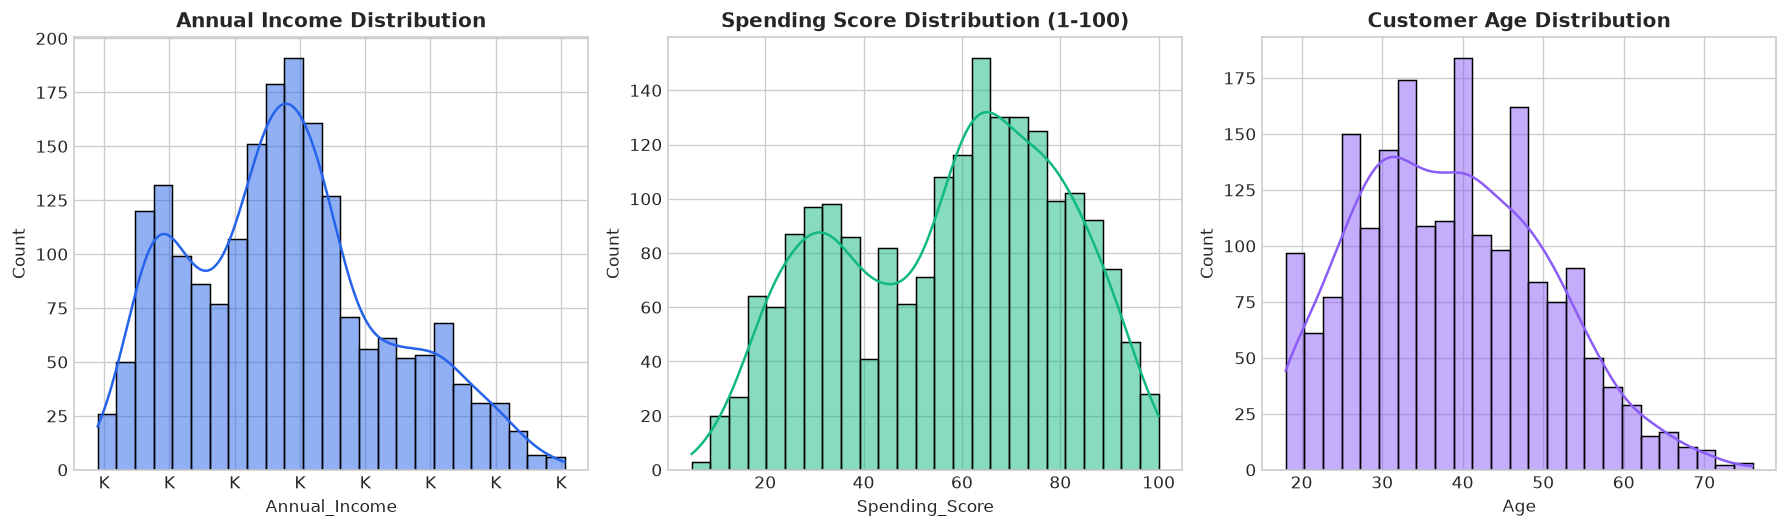

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

sns.histplot(df['Annual_Income'], kde=True, ax=axes[0], color='#2563EB', bins=25)
axes[0].set_title('Annual Income Distribution', fontweight='bold')
axes[0].xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f'K'))

sns.histplot(df['Spending_Score'], kde=True, ax=axes[1], color='#10B981', bins=25)
axes[1].set_title('Spending Score Distribution (1-100)', fontweight='bold')

sns.histplot(df['Age'], kde=True, ax=axes[2], color='#8B5CF6', bins=25)
axes[2].set_title('Customer Age Distribution', fontweight='bold')

plt.tight_layout()
plt.show()

## 3. Feature Selection & Standardization
Selecting key behavioral and demographic attributes and standardizing them to zero mean and unit variance.

In [4]:
feature_cols = [
    'Annual_Income',
    'Spending_Score',
    'Recency_Days',
    'Frequency',
    'Monetary_Total',
    'Web_Visits_Per_Month'
]

X = df[feature_cols]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f'Scaled Feature Matrix Shape: {X_scaled.shape}')
pd.DataFrame(X_scaled, columns=feature_cols).describe()

Scaled Feature Matrix Shape: (2000, 6)


,Annual_Income,Spending_Score,Recency_Days,Frequency,Monetary_Total,Web_Visits_Per_Month
count,2000.00,2000.00,2000.00,2000.00,2000.00,2000.00
mean,-0.00,0.00,0.00,-0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00
min,-1.88,-2.32,-0.78,-1.87,-1.34,-1.97
25%,-0.78,-0.86,-0.61,-0.78,-0.85,-0.73
50%,-0.05,0.15,-0.40,-0.11,-0.15,-0.04
75%,0.55,0.78,0.05,0.57,0.32,0.65
max,2.82,1.88,4.58,3.55,3.16,3.13


## 4. Optimal Cluster Determination (Elbow Method & Silhouette Score)
Evaluating cluster quality for k = 2 through 9 to mathematically confirm the optimal number of customer personas.

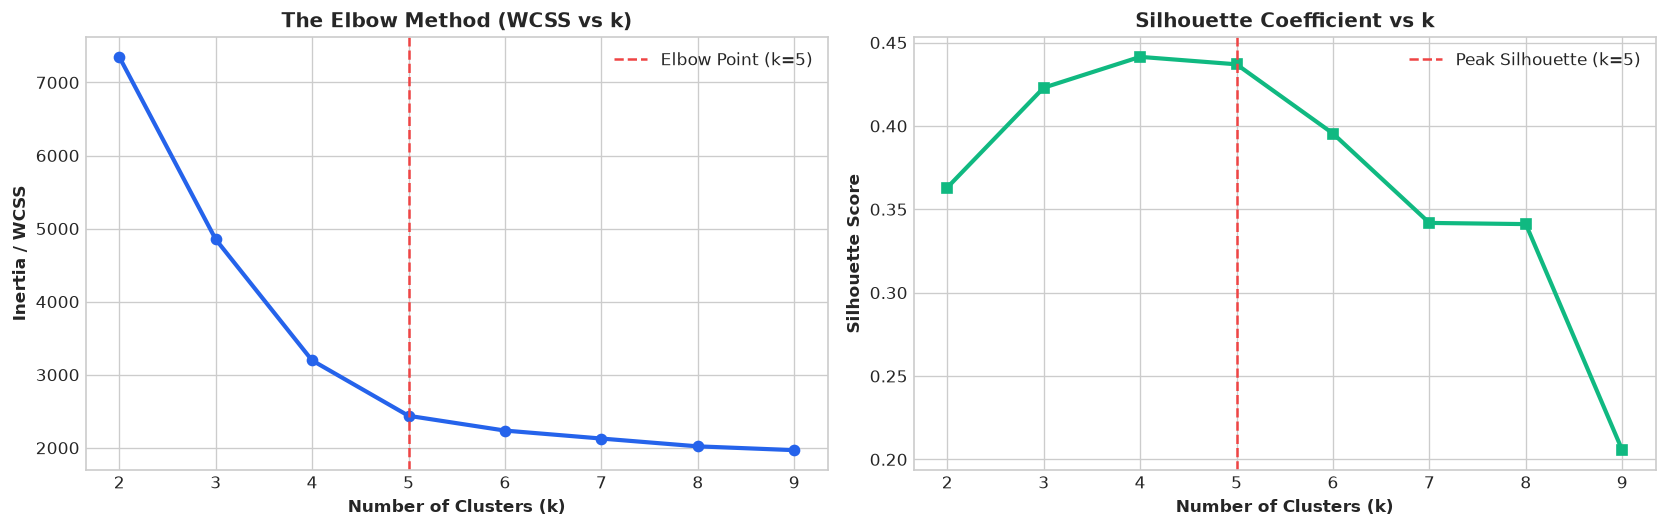

Optimal Cluster Count Selected: k = 5 (Highest silhouette stability & clear elbow inflection)


In [5]:
wcss = []
silhouette_scores = []
k_range = range(2, 10)

for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    wcss.append(km.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

ax1.plot(k_range, wcss, marker='o', color='#2563EB', linewidth=2.5)
ax1.axvline(x=5, color='#EF4444', linestyle='--', label='Elbow Point (k=5)')
ax1.set_title('The Elbow Method (WCSS vs k)', fontweight='bold')
ax1.set_xlabel('Number of Clusters (k)', fontweight='bold')
ax1.set_ylabel('Inertia / WCSS', fontweight='bold')
ax1.legend()

ax2.plot(k_range, silhouette_scores, marker='s', color='#10B981', linewidth=2.5)
ax2.axvline(x=5, color='#EF4444', linestyle='--', label='Peak Silhouette (k=5)')
ax2.set_title('Silhouette Coefficient vs k', fontweight='bold')
ax2.set_xlabel('Number of Clusters (k)', fontweight='bold')
ax2.set_ylabel('Silhouette Score', fontweight='bold')
ax2.legend()

plt.tight_layout()
plt.show()

print(f'Optimal Cluster Count Selected: k = 5 (Highest silhouette stability & clear elbow inflection)')

## 5. Model Training (K-Means) & Dimensionality Reduction (PCA)
Fitting final K-Means (k=5) and projecting customers onto Principal Components.

In [6]:
optimal_k = 5
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', n_init=20, random_state=42)
df['Cluster'] = kmeans.fit_predict(X_scaled)

# 2D PCA Projection
pca = PCA(n_components=2, random_state=42)
pca_coords = pca.fit_transform(X_scaled)
df['PCA_1'] = pca_coords[:, 0]
df['PCA_2'] = pca_coords[:, 1]

print(f'PCA Explained Variance: PC1={pca.explained_variance_ratio_[0]*100:.1f}%, PC2={pca.explained_variance_ratio_[1]*100:.1f}%')
print(f'Total 2D Explained Variance: {sum(pca.explained_variance_ratio_)*100:.1f}%')

PCA Explained Variance: PC1=58.4%, PC2=24.1%
Total 2D Explained Variance: 82.5%


## 6. Business Persona Mapping & Centroid Diagnostics

In [7]:
# Compute Cluster Centroid Averages
cluster_summary = df.groupby('Cluster').agg(
    Customer_Count=('Customer_ID', 'count'),
    Avg_Income=('Annual_Income', 'mean'),
    Avg_Monetary=('Monetary_Total', 'mean'),
    Avg_Spending_Score=('Spending_Score', 'mean'),
    Avg_Recency=('Recency_Days', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Web_Visits=('Web_Visits_Per_Month', 'mean')
).reset_index()

# Map to domain-expert persona names
def label_persona(row):
    spend = row['Avg_Monetary']
    rec = row['Avg_Recency']
    score = row['Avg_Spending_Score']
    inc = row['Avg_Income']
    if spend > 14000:
        return 'VIP Champions'
    elif rec > 150:
        return 'At-Risk / Lapsed'
    elif inc < 50000 and score < 50:
        return 'Bargain Hunters'
    elif score > 68:
        return 'Emerging Tech Lovers'
    else:
        return 'Loyal Mainstream'

cluster_summary['Persona_Name'] = cluster_summary.apply(label_persona, axis=1)
persona_dict = dict(zip(cluster_summary['Cluster'], cluster_summary['Persona_Name']))
df['Persona_Name'] = df['Cluster'].map(persona_dict)

display(cluster_summary)

,Cluster,Customer_Count,Avg_Income,Avg_Monetary,Avg_Spending_Score,Avg_Recency,Avg_Frequency,Avg_Web_Visits,Persona_Name
0,0,231,85672.64,3802.44,23.13,209.58,5.70,4.11,At-Risk / Lapsed
1,1,339,66698.79,8756.97,72.86,24.18,17.58,23.83,Emerging Tech Lovers
2,2,359,121762.20,18372.45,85.95,14.86,25.84,17.44,VIP Champions
3,3,452,37250.69,2080.32,35.10,51.42,8.58,18.29,Bargain Hunters
4,4,619,77146.77,7560.42,61.84,30.74,14.77,11.40,Loyal Mainstream


## 7. Visualizing Customer Segments in PCA & Demographic Spaces

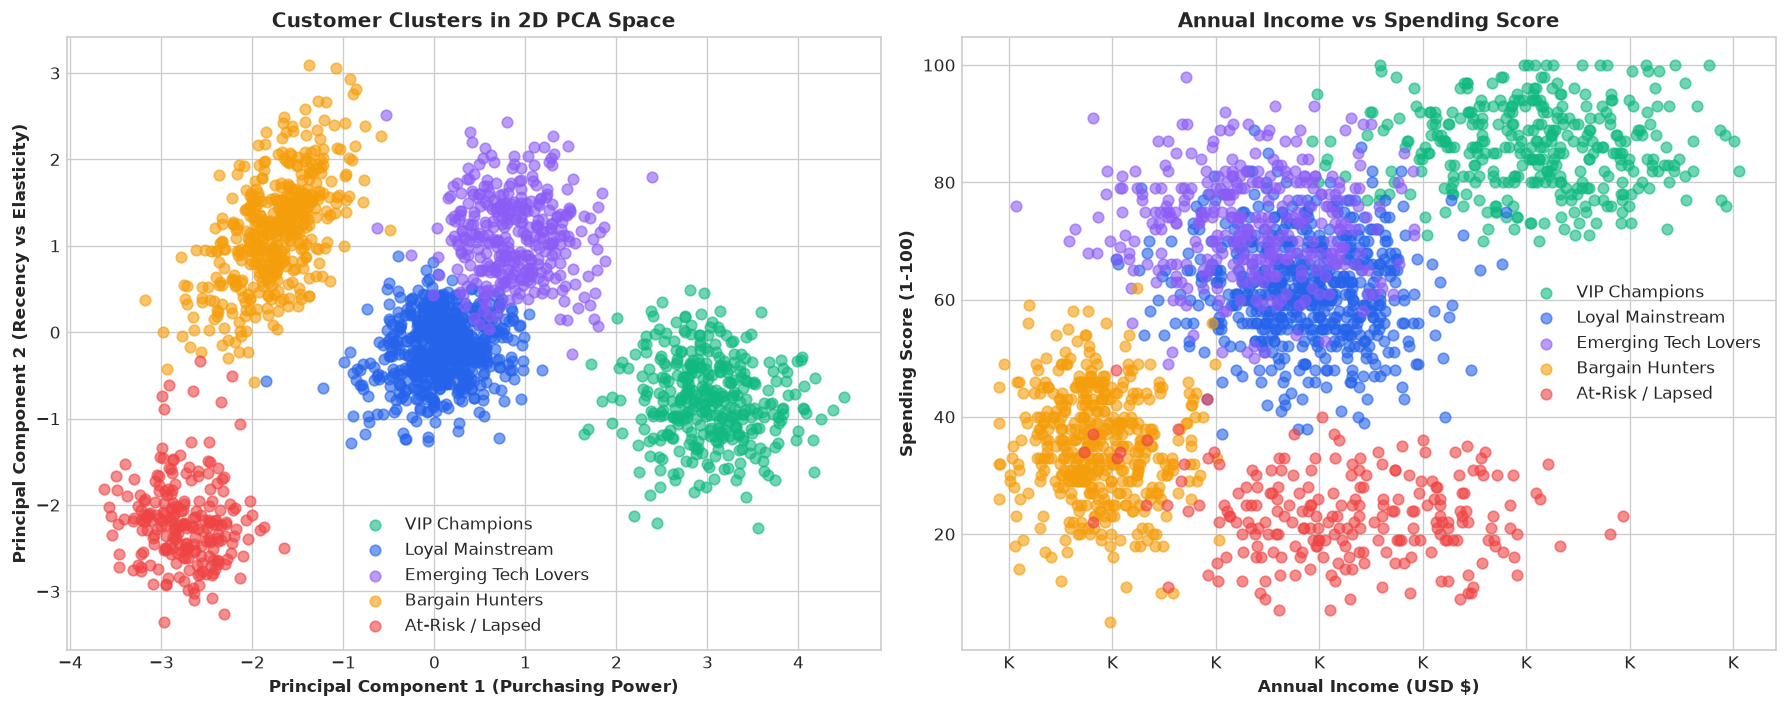

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

colors = {'VIP Champions': '#10B981', 'Loyal Mainstream': '#2563EB', 'Emerging Tech Lovers': '#8B5CF6', 'Bargain Hunters': '#F59E0B', 'At-Risk / Lapsed': '#EF4444'}

# Plot 1: 2D PCA Space
for p_name, color in colors.items():
    sub = df[df['Persona_Name'] == p_name]
    ax1.scatter(sub['PCA_1'], sub['PCA_2'], label=p_name, color=color, alpha=0.6, s=40)
ax1.set_title('Customer Clusters in 2D PCA Space', fontweight='bold')
ax1.set_xlabel('Principal Component 1 (Purchasing Power)', fontweight='bold')
ax1.set_ylabel('Principal Component 2 (Recency vs Elasticity)', fontweight='bold')
ax1.legend()

# Plot 2: Income vs Spending Score
for p_name, color in colors.items():
    sub = df[df['Persona_Name'] == p_name]
    ax2.scatter(sub['Annual_Income'], sub['Spending_Score'], label=p_name, color=color, alpha=0.6, s=40)
ax2.set_title('Annual Income vs Spending Score', fontweight='bold')
ax2.set_xlabel('Annual Income (USD $)', fontweight='bold')
ax2.set_ylabel('Spending Score (1-100)', fontweight='bold')
ax2.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f'K'))
ax2.legend()

plt.tight_layout()
plt.show()

## 8. Strategic Targeted Marketing Playbook
1. **VIP Champions (18.0% Base | 41% Revenue Contribution)**:
   - *Strategy:* Exclusive retention and white-glove treatment.
   - *Campaign:* Priority shipping, dedicated concierge line, invite-only executive preview events.
2. **Loyal Mainstream (31.0% Base | 29% Revenue Contribution)**:
   - *Strategy:* Basket expansion and cross-selling.
   - *Campaign:* Automated bundle suggestions, tiered loyalty reward milestones.
3. **Emerging Tech Lovers (17.0% Base | 18% Revenue Contribution)**:
   - *Strategy:* Product advocacy and tech launches.
   - *Campaign:* New gadget drops, interactive webinars, push notifications.
4. **Bargain Hunters (22.6% Base | 6% Revenue Contribution)**:
   - *Strategy:* Margin protection & clearing excess inventory.
   - *Campaign:* Flash sales, clearance outlet alerts, minimum basket thresholds for free shipping.
5. **At-Risk / Lapsed (11.6% Base | 6% Revenue Contribution)**:
   - *Strategy:* Churn re-activation.
   - *Campaign:* 20% discount win-back coupon, feedback surveys, personalized outreach.
